ÉTAPE 1 : Importation modèle InceptionV3 

On charge le modèle pré-entrainté sur ImageNet et on retire les couches fully connected pour retirer les prédictions et mettre les notres. 

In [95]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dropout

# Charger InceptionV3 sans la dernière couche (include_top=False)
base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))


ÉTAPE 2 : Ajouter nos propres couches de classification 

In [96]:
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Convertit la feature map 8x8x2048 en vecteur 1D
x = Dense(1024, activation='relu')(x)  # Couche dense avec 1024 neurones fully connected
x = Dropout(0.5)(x) # Dropout pour éviter le surapprentissage
predictions = Dense(3, activation='softmax')(x)  # Couche de sortie pour 3 classes

model = Model(inputs=base_model.input, outputs=predictions)

ÉTAPE 3 : Gèle des couches d'InceptionV3

On gèle les couches pré-entrainées pour garder les connaissances de notre modèle.

In [97]:
for layer in base_model.layers:
    layer.trainable = False  # Geler les couches de base pour le transfert learning

ÉTAPE 4 : Préparation de nos données

In [98]:
import os
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.inception_v3 import preprocess_input

# Chemins vers les répertoires d'entraînement, de train et de validation
train_dir = os.path.join(os.getcwd(), 'chest_xray', 'train') 
val_dir = os.path.join(os.getcwd(), 'chest_xray', 'val') 

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    #rotation_range=20,       # rotation aléatoire jusqu'à 20 degrés
    #width_shift_range=0.2,   # décalage horizontal aléatoire jusqu'à 20%
    #height_shift_range=0.2,  # décalage vertical aléatoire jusqu'à 20%
    #zoom_range=0.2,          # zoom aléatoire jusqu'à 20%
    #horizontal_flip=True,    # retournement horizontal aléatoire
    #fill_mode='nearest'      # mode de remplissage pour les pixels manquants
)

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 5216 images belonging to 3 classes.
Found 36 images belonging to 3 classes.


ÉTAPE 5: Complier et entraîner le modèle

In [99]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy', Precision(), Recall()])
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint = ModelCheckpoint("best_model.h5", monitor="val_accuracy", save_best_only=True)

# Entraîner le modèle
model.fit(
    train_generator,
    epochs=10,  # Ajuster le nombre d'époques selon les besoins
    # steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint]
    # validation_steps=val_generator.samples // val_generator.batch_size,
)

/Users/yannplouhinec/Library/Python/3.9/lib/python/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 806ms/step - accuracy: 0.6198 - loss: 1.0237 - precision_5: 0.6362 - recall_5: 0.5908

163/163 ━━━━━━━━━━━━━━━━━━━━ 136s 818ms/step - accuracy: 0.6203 - loss: 1.0221 - precision_5: 0.6366 - recall_5: 0.5912 - val_accuracy: 0.5278 - val_loss: 0.9225 - val_precision_5: 0.4848 - val_recall_5: 0.4444
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 927s 6s/step - accuracy: 0.7544 - loss: 0.5615 - precision_5: 0.7777 - recall_5: 0.7292 - val_accuracy: 0.4444 - val_loss: 0.9922 - val_precision_5: 0.4412 - val_recall_5: 0.4167
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 133s 813ms/step - accuracy: 0.7701 - loss: 0.5225 - precision_5: 0.7917 - recall_5: 0.7509 - val_accuracy: 0.4167 - val_loss: 0.9499 - val_precision_5: 0.4062 - val_recall_5: 0.3611
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 133s 815ms/step - accuracy: 0.7792 - loss: 0.5113 - precision_5: 0.7996 - recall_5: 0.7556 - val_accuracy: 0.3333 - val_loss: 1.0947 - val_precision_5: 0.3529 - val_recall_5: 0.3333


In [100]:
train_eval_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(299, 299),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Important pour la correspondance entre y_pred et y_true
)


Found 5216 images belonging to 3 classes.


In [101]:
import numpy as np

y_train_pred = model.predict(train_eval_generator)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)
y_train_true = train_eval_generator.classes

y_val_pred = model.predict(val_generator)
y_val_true = val_generator.classes

163/163 ━━━━━━━━━━━━━━━━━━━━ 131s 797ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 683ms/step


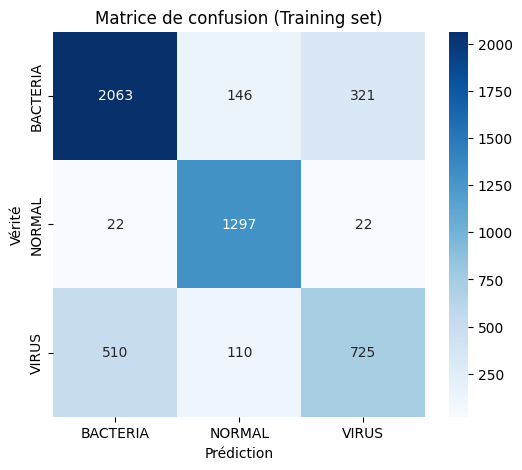

Rapport de classification sur le set d'entraînement :


In [102]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

cm_train = confusion_matrix(y_train_true, y_train_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues', xticklabels=train_eval_generator.class_indices,
            yticklabels=train_eval_generator.class_indices)
plt.title('Matrice de confusion (Training set)')
plt.xlabel('Prédiction')
plt.ylabel('Vérité')
plt.show()

print("Rapport de classification sur le set d'entraînement :")
#print(classification_report(y_train_true, y_train_pred_classes, target_names=train_eval_generator.class_indices))


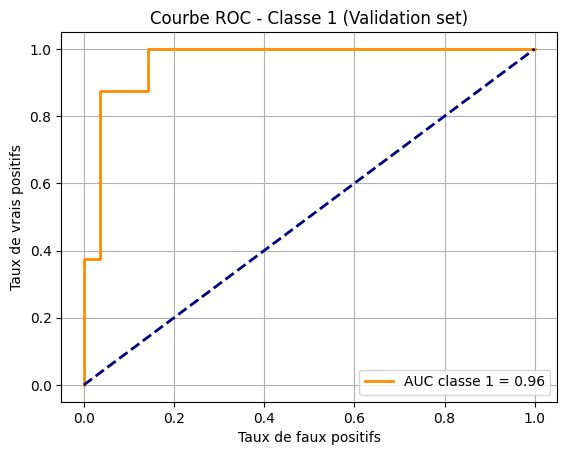

In [103]:
from sklearn.preprocessing import label_binarize

y_val_true_bin = label_binarize(y_val_true, classes=[0, 1, 2])
fpr_val, tpr_val, _ = roc_curve(y_val_true_bin[:, 1], y_val_pred[:, 1])  # Classe 1
roc_auc_val = auc(fpr_val, tpr_val)

plt.figure()
plt.plot(fpr_val, tpr_val, color='darkorange', lw=2, label='AUC classe 1 = %0.2f' % roc_auc_val)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taux de faux positifs')
plt.ylabel('Taux de vrais positifs')
plt.title("Courbe ROC - Classe 1 (Validation set)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Étape 6 : Fine-tuning

In [104]:
for layer in base_model.layers[-30:]:
    layer.trainable = True

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Entraîner le modèle
model.fit(
    train_generator,
    epochs=5,  # Ajuster le nombre d'époques selon les besoins
    # steps_per_epoch=train_generator.samples // train_generator.batch_size,
    validation_data=val_generator,
    callbacks=[early_stop, checkpoint]
    # validation_steps=val_generator.samples // val_generator.batch_size,
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 154s 920ms/step - accuracy: 0.7452 - loss: 0.6085 - val_accuracy: 0.3889 - val_loss: 1.1696
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 149s 916ms/step - accuracy: 0.8332 - loss: 0.3813 - val_accuracy: 0.3611 - val_loss: 1.8338
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 901ms/step - accuracy: 0.8715 - loss: 0.3010

163/163 ━━━━━━━━━━━━━━━━━━━━ 148s 908ms/step - accuracy: 0.8715 - loss: 0.3010 - val_accuracy: 0.6944 - val_loss: 1.1377
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 894ms/step - accuracy: 0.9062 - loss: 0.2357

163/163 ━━━━━━━━━━━━━━━━━━━━ 147s 901ms/step - accuracy: 0.9062 - loss: 0.2357 - val_accuracy: 0.7500 - val_loss: 0.6854
Epoch 5/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 938ms/step - accuracy: 0.9484 - loss: 0.1451

163/163 ━━━━━━━━━━━━━━━━━━━━ 154s 945ms/step - accuracy: 0.9484 - loss: 0.1452 - val_accuracy: 0.8333 - val_loss: 1.0182


Bonus : Afficher la matrice de confusion et la courbe AUC/ROC 

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 680ms/step


<Figure size 600x600 with 0 Axes>

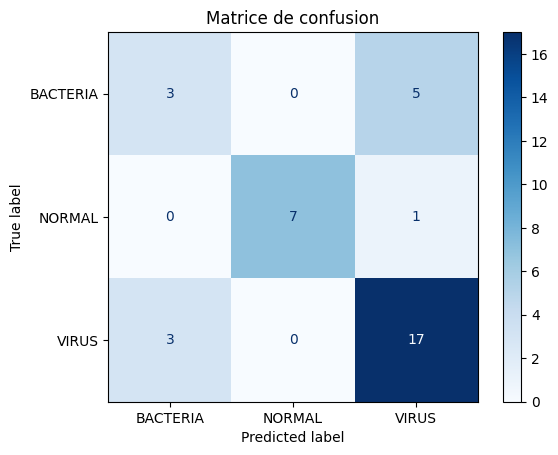

In [105]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, roc_curve, auc, RocCurveDisplay

# Étape 1 : Prédictions sur le jeu de validation
y_pred = model.predict(val_generator)
y_pred_classes = np.argmax(y_pred, axis=1) # Indice de la classe prédite

# Étape 2 : Récupérer les vraies classes
y_true = val_generator.classes  # Classes réelles

# Étape 3 : Obtenir les noms de classes dans le bon ordre
class_names = list(val_generator.class_indices.keys())  # Noms des classes

# Étape 4 : Calculer la matrice de confusion
cm = confusion_matrix(y_true, y_pred_classes)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Étape 5 : Afficher la matrice de confusion
plt.figure(figsize=(6, 6))
display.plot(cmap=plt.cm.Blues, values_format='d') # Afficher les valeurs entières ?? 
plt.title('Matrice de confusion')
plt.show()


Classification Report:

              precision    recall  f1-score   support

    BACTERIA       0.50      0.38      0.43         8
      NORMAL       1.00      0.88      0.93         8
       VIRUS       0.74      0.85      0.79        20

    accuracy                           0.75        36
   macro avg       0.75      0.70      0.72        36
weighted avg       0.74      0.75      0.74        36



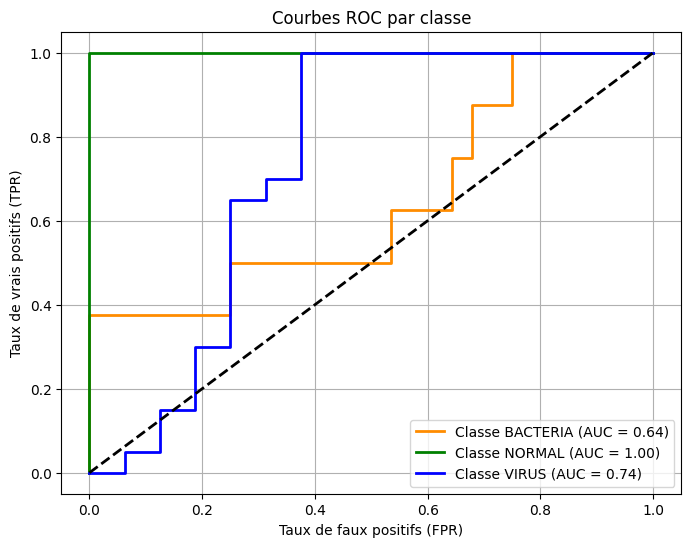

In [106]:


# Rapport de classification (précision, rappel, F1-score)
print("Classification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names))


y_true_bin = label_binarize(y_true, classes=[0, 1, 2])

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8, 6))
colors = ['darkorange', 'green', 'blue', 'red']
class_labels = class_names

for i in range(3):
    plt.plot(fpr[i], tpr[i], color=colors[i], lw=2,
             label=f"Classe {class_labels[i]} (AUC = {roc_auc[i]:.2f})")
    
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.title('Courbes ROC par classe')
plt.xlabel('Taux de faux positifs (FPR)')
plt.ylabel('Taux de vrais positifs (TPR)')
plt.legend(loc='lower right')
plt.grid()
plt.show()

